In [1]:
# Install required libraries if needed
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
# Import required libraries

import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load Titanic Dataset Automatically

import pandas as pd
from pathlib import Path

def load_titanic_data():

    dataset_url = (
        "https://raw.githubusercontent.com/"
        "datasciencedojo/datasets/master/titanic.csv"
    )

    try:
        # First check the current notebook directory
        local_file = Path("train.csv")

        if local_file.exists():
            data = pd.read_csv(local_file)
            print("Dataset loaded from local file.")

        else:
            # Download dataset automatically
            print("Downloading Titanic dataset...")

            data = pd.read_csv(dataset_url)

            print("Dataset downloaded successfully!")

        # Validate dataset columns
        required_columns = [
            "Survived", "Pclass", "Sex", "Age",
            "SibSp", "Parch", "Fare", "Cabin", "Embarked"
        ]

        missing = [
            col for col in required_columns
            if col not in data.columns
        ]

        if missing:
            raise ValueError(
                f"Dataset is missing columns: {missing}"
            )

        return data

    except Exception as error:
        raise RuntimeError(
            f"Unable to load Titanic dataset: {error}"
        ) from error


# Load dataset
df = load_titanic_data()

print("\nDataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())

print("\nDataset loaded successfully!")

Dataset downloaded successfully!

Dataset Shape: (891, 12)

First Five Records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset loaded successfully!


In [4]:
# Initial dataset inspection

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Survived"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Statistical Summary:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN



Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate Records: 0

Target Distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [5]:
def clean_and_engineer_features(data):
    """
    Clean Titanic data and create meaningful features.
    """
    data = data.copy()

    # Remove duplicate records
    data.drop_duplicates(inplace=True)

    # Remove rows with missing target values
    data.dropna(subset=["Survived"], inplace=True)

    # Ensure target is numeric
    data["Survived"] = pd.to_numeric(
        data["Survived"], errors="coerce"
    )

    data.dropna(subset=["Survived"], inplace=True)

    # Validate target labels
    data = data[data["Survived"].isin([0, 1])].copy()

    # Family size feature
    data["FamilySize"] = (
        data["SibSp"].fillna(0)
        + data["Parch"].fillna(0)
        + 1
    )

    # Cabin letter feature
    if "Cabin" in data.columns:
        data["CabinLetter"] = (
            data["Cabin"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .str[0]
        )
    else:
        data["CabinLetter"] = "Unknown"

    # IsAlone feature
    data["IsAlone"] = (
        data["FamilySize"] == 1
    ).astype(int)

    return data


df = clean_and_engineer_features(df)

print("Data cleaning and feature engineering completed!")

display(
    df[
        ["Survived", "FamilySize", "CabinLetter", "IsAlone"]
    ].head(10)
)

print("\nCleaned dataset shape:", df.shape)

Data cleaning and feature engineering completed!


,Survived,FamilySize,CabinLetter,IsAlone
0,0,2,U,0
1,1,2,C,0
2,1,1,U,1
3,1,2,C,0
4,0,1,U,1
5,0,1,U,1
6,0,1,E,1
7,0,5,U,0
8,1,3,U,0
9,1,2,U,0



Cleaned dataset shape: (891, 15)


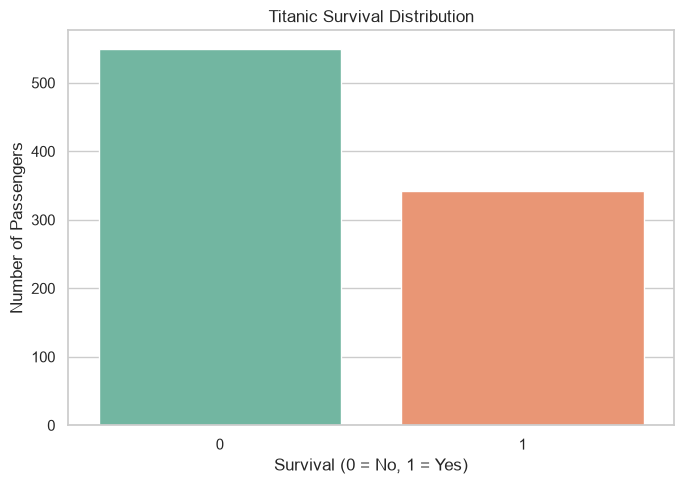

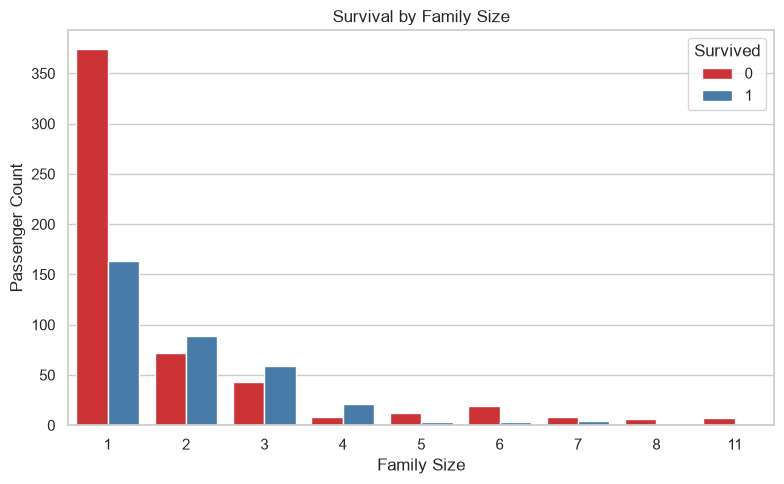

In [6]:
# Analyze survival distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    palette="Set2",
    legend=False
)

plt.title("Titanic Survival Distribution")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


# Family size vs survival

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="FamilySize",
    hue="Survived",
    palette="Set1"
)

plt.title("Survival by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Passenger Count")
plt.tight_layout()
plt.show()

In [7]:
# Separate input features and target variable

target = "Survived"

numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]

categorical_features = [
    "Sex",
    "Embarked",
    "CabinLetter"
]

# Validate required columns
required_columns = (
    numeric_features + categorical_features + [target]
)

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

X = df[numeric_features + categorical_features].copy()
y = df[target].astype(int)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Input features shape: (891, 10)
Target shape: (891,)

Numerical Features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Categorical Features: ['Sex', 'Embarked', 'CabinLetter']


In [8]:
# Create preprocessing pipelines

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical features: Imputation + Standard Scaling")
print("Categorical features: Imputation + One-Hot Encoding")

Preprocessing pipeline created successfully!
Numerical features: Imputation + Standard Scaling
Categorical features: Imputation + One-Hot Encoding


In [9]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


In [10]:
# Initialize Random Forest Classifier

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Complete machine learning pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", random_forest)
    ]
)

# Train model

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [11]:
# Generate predictions

y_pred = model.predict(X_test)

# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("=" * 50)
print("TITANIC SURVIVAL MODEL EVALUATION")
print("=" * 50)

print(f"\nModel Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Survived", "Survived"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

TITANIC SURVIVAL MODEL EVALUATION

Model Accuracy: 80.45%

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.79      0.94      0.85       110
    Survived       0.85      0.59      0.70        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179


Confusion Matrix:
[[103   7]
 [ 28  41]]


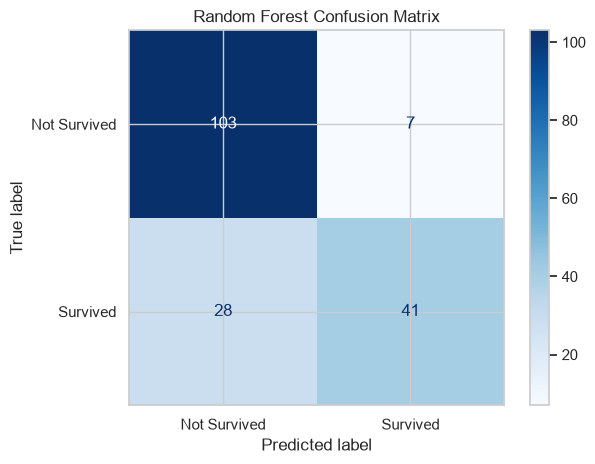

In [12]:
# Visualize confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
# Perform 5-fold cross-validation on training data

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)

print(
    f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: {cv_scores.std() * 100:.2f}%"
)

Cross-validation scores: [0.7972028  0.76923077 0.80985915 0.83098592 0.84507042]
Mean CV Accuracy: 81.05%
Standard Deviation: 2.64%


In [14]:
# Extract feature importance from trained model

trained_classifier = model.named_steps["classifier"]

feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Feature Importance Ranking:")
display(importance_df.head(15))

Feature Importance Ranking:


,Feature,Importance
0,categorical__Sex_female,0.210594
1,categorical__Sex_male,0.204845
2,numeric__Fare,0.147770
3,numeric__Age,0.108464
4,numeric__Pclass,0.086044
5,categorical__CabinLetter_U,0.055054
6,numeric__FamilySize,0.050520
7,numeric__SibSp,0.025158
8,numeric__Parch,0.020098
9,numeric__IsAlone,0.016653


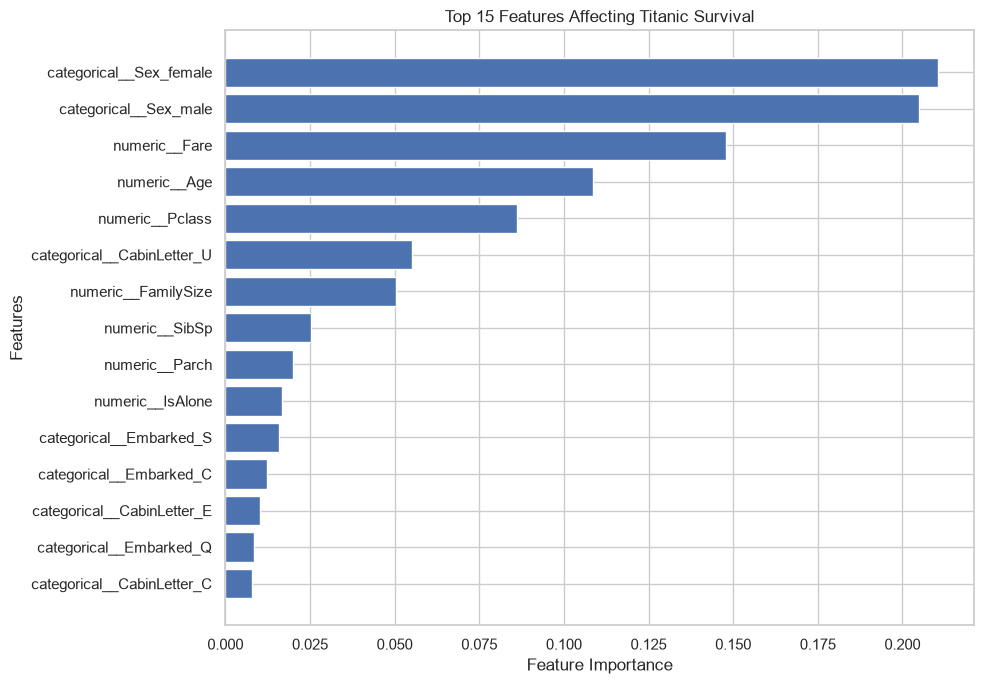

In [15]:
# Visualize top 15 important features

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Affecting Titanic Survival")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [16]:
def generate_project_report(
    accuracy,
    cv_scores,
    importance_df,
    output_path="Titanic_Feature_Engineering_Report.txt"
):
    """
    Generate a project report using actual model results.
    """

    top_features = importance_df.head(5)

    report = f"""
TITANIC SURVIVAL PREDICTION
FEATURE ENGINEERING PROJECT REPORT
=====================================

1. PROJECT OBJECTIVE

The objective is to predict passenger survival
using engineered features and a Random Forest
classification algorithm.

2. DATA PREPROCESSING

- Missing numerical values handled using median.
- Missing categorical values handled using mode.
- Categorical variables encoded using One-Hot Encoding.
- Numerical variables scaled using StandardScaler.
- Duplicate records removed.

3. FEATURE ENGINEERING

- FamilySize: SibSp + Parch + 1
- CabinLetter: Extracted from Cabin.
- IsAlone: Identifies passengers travelling alone.

4. MACHINE LEARNING MODEL

Algorithm: Random Forest Classifier
Number of estimators: 300
Maximum depth: 8
Train-test split: 80:20

5. MODEL PERFORMANCE

Test Accuracy: {accuracy * 100:.2f}%

Mean Cross-Validation Accuracy:
{cv_scores.mean() * 100:.2f}%

Cross-Validation Standard Deviation:
{cv_scores.std() * 100:.2f}%

6. TOP FIVE IMPORTANT FEATURES

"""

    for index, row in top_features.iterrows():
        report += (
            f"{index + 1}. {row['Feature']}: "
            f"{row['Importance']:.4f}\n"
        )

    report += """
7. CONCLUSION

The Random Forest Classifier was trained using
engineered Titanic passenger features.

The model was evaluated using test accuracy,
classification metrics, confusion matrix and
cross-validation.

Feature importance analysis was performed to
identify the most influential predictive features.

The experiment demonstrates how feature
engineering and machine learning can be combined
to predict passenger survival.
"""

    Path(output_path).write_text(
        report,
        encoding="utf-8"
    )

    print(f"Project report saved: {output_path}")


generate_project_report(
    accuracy,
    cv_scores,
    importance_df
)

Project report saved: Titanic_Feature_Engineering_Report.txt


In [17]:
# Save trained model

joblib.dump(
    model,
    "titanic_survival_model.pkl"
)

# Save feature importance results

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

# Save cleaned dataset

df.to_csv(
    "cleaned_titanic_dataset.csv",
    index=False
)

print("All project files saved successfully!")

All project files saved successfully!


In [18]:
# Final project validation

required_outputs = [
    "Titanic_Feature_Engineering_Report.txt",
    "titanic_survival_model.pkl",
    "feature_importance.csv",
    "cleaned_titanic_dataset.csv"
]

print("=" * 50)
print("FINAL PROJECT VALIDATION")
print("=" * 50)

for filename in required_outputs:
    file_exists = Path(filename).exists()

    print(
        f"{filename}: "
        f"{'SUCCESS' if file_exists else 'FAILED'}"
    )

print("\nFinal Model Accuracy:", f"{accuracy * 100:.2f}%")
print("Cross-Validation Mean:", f"{cv_scores.mean() * 100:.2f}%")

print("\nProject implementation completed!")

FINAL PROJECT VALIDATION
Titanic_Feature_Engineering_Report.txt: SUCCESS
titanic_survival_model.pkl: SUCCESS
feature_importance.csv: SUCCESS
cleaned_titanic_dataset.csv: SUCCESS

Final Model Accuracy: 80.45%
Cross-Validation Mean: 81.05%

Project implementation completed!
